# Cell-Type Annotation and Evaluation

This notebook assigns detailed Lung and tumor-microenvironment labels to final clusters with a frozen CellMarker panel. Source-provided `Cell_type` labels are used for visualization and evaluation.

In [1]:
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import seaborn as sns
import umap
import yaml
from IPython.display import Markdown, display

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

with open('configs/default.yml') as file:
    config = yaml.safe_load(file)
with open(config['annotation']['marker_panel_file']) as file:
    marker_config = yaml.safe_load(file)

seed = config['analysis']['random_seed']
representation_settings = config['representation']
latent_dim = representation_settings['latent_dim']
label_order = list(marker_config['labels'])
reference_order = marker_config['evaluation']['source_label_order']
figure_dir = 'outputs/figures'
os.makedirs(figure_dir, exist_ok=True)

assignments = pd.read_csv('outputs/clusters/clustering-labels.csv.gz', index_col='cell_id')
annotation_labels = pd.read_csv('outputs/annotations/annotation-labels.csv.gz', index_col='cell_id')
cluster_labels = pd.read_csv('outputs/tables/annotation-cluster-labels.csv')
marker_genes = pd.read_csv('outputs/tables/annotation-cluster-marker-genes.csv')
marker_scores = pd.read_csv('outputs/tables/annotation-cluster-marker-scores.csv')
annotation_evaluation = pd.read_csv('outputs/tables/annotation-evaluation.csv')
per_type = pd.read_csv('outputs/tables/annotation-per-type-evaluation.csv')
confusion = pd.read_csv('outputs/tables/annotation-confusion-matrix.csv')

pca_embedding = pd.read_csv(f'outputs/embeddings/pca-{latent_dim}.csv.gz', index_col='cell_id').loc[assignments.index]
autoencoder_embedding = pd.read_csv(f'outputs/embeddings/autoencoder-{latent_dim}.csv.gz', index_col='cell_id').loc[assignments.index]
specifications = [('pca', 'kmeans'), ('pca', 'leiden'), ('autoencoder', 'kmeans'), ('autoencoder', 'leiden')]
sns.set_theme(style='whitegrid', context='notebook')

/Users/ren/anaconda3/envs/lung-tumor-cell-type-identification/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Marker panel

The 15 labels form an independent Lung and tumor-microenvironment panel curated from CellMarker 2.0 Human records with `tissue_type = Lung`, including lung-cancer entries when available. It covers major lymphoid, myeloid, epithelial, vascular, and stromal populations expected in lung tissue. Each label uses six canonical markers from this reference, and the same frozen panel is used for all four clustering combinations.

In [2]:
panel_table = pd.DataFrame({
    'Cell type': label_order,
    'Marker genes': [', '.join(marker_config['labels'][label]) for label in label_order]
})
display(panel_table)
print(f"Source: {marker_config['source']['database']} ({marker_config['source']['downloaded_file']})")

,Cell type,Marker genes
0,T cell,"CD3D, CD3E, TRAC, LCK, IL7R, CD247"
1,B cell,"MS4A1, CD79A, CD19, CD74, CD37, HLA-DRA"
2,Plasma cell,"MZB1, XBP1, SDC1, JCHAIN, TNFRSF17, CD38"
3,NK cell,"NKG7, KLRD1, GNLY, NCR1, KLRF1, PRF1"
4,Macrophage,"CD68, CD163, MRC1, C1QC, C1QB, APOE"
5,Monocyte,"LYZ, S100A8, S100A9, FCN1, CTSD, LILRB1"
6,Dendritic cell,"FCER1A, CD1C, CLEC10A, CD83, CD209, HLA-DRA"
7,Mast cell,"TPSB2, TPSAB1, KIT, CPA3, MS4A2, GATA2"
8,Epithelial cell,"EPCAM, CDH1, KRT8, KRT18, KRT19, KRT7"
9,Endothelial cell,"PECAM1, VWF, CDH5, CLDN5, RAMP2, KDR"


Source: CellMarker 2.0 (Cell_marker_Human.xlsx)


## Marker score and annotation

For label $t$ with marker set $M_t$, let $y_{ig}$ be the log-normalized expression of gene $g$ in cell $i$. The cell-level marker score subtracts the mean expression of control genes $C_t$, sampled from expression bins matched to the marker genes:

$$s_{it} = \frac{1}{|M_t|}\sum_{g \in M_t} y_{ig} - \frac{1}{|C_t|}\sum_{g \in C_t} y_{ig}$$

The cluster-level score is:

$$S_{ct} = \frac{1}{|c|}\sum_{i \in c}s_{it}$$

The predicted label is $\operatorname{argmax}_t S_{ct}$. Wilcoxon tests compare each cluster with all remaining cells. Top genes are ordered by their positive Wilcoxon z-score, while `logfoldchanges` and adjusted p-values provide complementary effect-size and significance information.

In [3]:
def sort_clusters(frame):
    return frame.sort_values('cluster', key=lambda values: values.astype(int))

for representation, method in specifications:
    display(Markdown(f'### {representation.title()} + {method.title()}'))
    evidence = sort_clusters(cluster_labels.loc[
        (cluster_labels['representation'] == representation)
        & (cluster_labels['method'] == method),
        ['cluster', 'predicted_label', 'predicted_score', 'supporting_markers']
    ]).set_index('cluster')
    evidence.index.name = 'Cluster'
    display(evidence.round(4))

    top_markers = sort_clusters(marker_genes.loc[
        (marker_genes['representation'] == representation)
        & (marker_genes['method'] == method)
    ].groupby('cluster', group_keys=False).head(5)).sort_values(['cluster', 'rank'])
    top_markers = top_markers.set_index(['cluster', 'rank'])[[
        'gene', 'z_score', 'logfoldchanges', 'pvals_adj'
    ]]
    top_markers.index.names = ['Cluster', 'Rank']
    display(top_markers.round(4))

### Pca + Kmeans

,predicted_label,predicted_score,supporting_markers
Cluster,,,
0,Macrophage,1.4154,CD68
1,T cell,0.8052,"TRAC, CD3D, CD3E"
2,Epithelial cell,1.2366,"KRT18, KRT19, KRT8, EPCAM, KRT7"
3,B cell,1.8192,"CD79A, CD74, MS4A1, CD37, HLA-DRA"
4,Fibroblast,1.7751,"DCN, COL1A2"
5,Mast cell,3.0753,"TPSB2, TPSAB1, CPA3, MS4A2, GATA2"


gene   z_score  logfoldchanges  pvals_adj
Cluster Rank                                             
0       1     TYROBP  137.7732          5.8761        0.0
        2       AIF1  135.6390          6.4510        0.0
        3        FTL  133.2799          3.9586        0.0
        4        LYZ  132.5541          6.5124        0.0
        5     FCER1G  131.5328          5.4861        0.0
1       1       IL32  158.3218          4.9459        0.0
        2       TRAC  145.4917          5.8448        0.0
        3       CD3D  142.2468          6.1316        0.0
        4        B2M  141.7762          1.5444        0.0
        5       BTG1  131.0210          2.4982        0.0
2       1      WFDC2  120.5315          6.6141        0.0
        2       MUC1  118.7816          6.2758        0.0
        3      MGST1  118.2064          5.5113        0.0
        4       ELF3  115.5674          6.5530        0.0
        5      KRT18  114.1935          5.7373        0.0
3       1      CD79A  103.2952          7.6843        0.0
        2       IGKC   81.7793          3.8665        0.0
        3       CD74   65.8673          2.1755        0.0
        4      MS4A1   65.8153          6.7296        0.0
        5      IGHA1   63.9395          3.0516        0.0
4       1     IGFBP7   75.5369          7.5399        0.0
        2        MGP   73.2183          7.6359        0.0
        3      CALD1   73.0069          7.6066        0.0
        4      SPARC   70.9675          7.0784        0.0
        5     IFITM3   70.8866          4.1374        0.0
5       1      TPSB2   72.0991         11.5316        0.0
        2     TPSAB1   72.0975         12.4441        0.0
        3       CPA3   69.9819         10.6952        0.0
        4      HPGDS   66.4681          7.8499        0.0
        5      MS4A2   65.0260         11.0740        0.0

### Pca + Leiden

,predicted_label,predicted_score,supporting_markers
Cluster,,,
0,T cell,0.8774,"TRAC, CD3D, CD3E"
1,Macrophage,1.8041,"CD68, APOE, C1QB, C1QC"
2,T cell,0.9131,"TRAC, CD3D, CD3E, IL7R"
3,T cell,0.8251,"CD3D, TRAC, CD3E"
4,B cell,2.2924,"CD79A, CD37, MS4A1, CD74, HLA-DRA"
5,B cell,1.2690,"HLA-DRA, CD74"
6,Epithelial cell,1.1679,KRT18
7,Epithelial cell,0.8807,NaN
8,Mast cell,3.0701,"TPSB2, TPSAB1, CPA3, MS4A2, GATA2"


gene  z_score  logfoldchanges  pvals_adj
Cluster Rank                                            
0       1       IGKC  94.5298          2.8559        0.0
        2       TRAC  81.7055          2.9782        0.0
        3      IGLC2  79.3648          2.5083        0.0
        4       IL32  77.8194          2.6981        0.0
        5        B2M  75.3650          1.0994        0.0
...              ...      ...             ...        ...
16      1      RAMP2  40.7967         10.2366        0.0
        2      GNG11  40.1644          6.9988        0.0
        3     IFITM3  39.0498          4.3466        0.0
        4      CLDN5  38.9390         10.5986        0.0
        5       CAV1  38.7622          6.5861        0.0

[85 rows x 4 columns]

... (2 outputs left out)

gene   z_score  logfoldchanges  pvals_adj
Cluster Rank                                              
0       1      IGFBP7   75.8592          7.4814        0.0
        2       CALD1   73.5013          7.6624        0.0
        3         MGP   73.3462          7.5566        0.0
        4      IFITM3   71.6963          4.1204        0.0
        5       SPARC   71.4238          7.0875        0.0
1       1      TYROBP  138.2526          5.8778        0.0
        2        AIF1  136.7620          6.5694        0.0
        3         FTL  133.6758          3.9404        0.0
        4         LYZ  132.1022          6.4856        0.0
        5      FCER1G  131.6133          5.4758        0.0
2       1       SFTPB  103.5241          7.2698        0.0
        2       NAPSA  100.1655          6.3333        0.0
        3     SLC34A2   99.2776          6.3290        0.0
        4       SFTA2   98.5475          5.7375        0.0
        5        MUC1   96.6539          5.2521        0.0
3       1       KRT19   75.4362          5.5746        0.0
        2        KRT7   73.6192          5.4262        0.0
        3       KRT18   70.9584          4.9052        0.0
        4        KRT8   70.6492          4.8396        0.0
        5       CLDN3   69.6689          5.5138        0.0
4       1       TPSB2   71.9658         11.4839        0.0
        2      TPSAB1   71.9168         12.4084        0.0
        3        CPA3   69.8175         10.6893        0.0
        4       HPGDS   66.3395          7.8299        0.0
        5       MS4A2   64.8461         11.0904        0.0
5       1        TRAC  106.0316          3.5442        0.0
        2         LTB   99.0297          3.4760        0.0
        3        IL32   95.2715          3.0182        0.0
        4         CD2   89.5861          3.0177        0.0
        5        CD3D   88.5129          2.8949        0.0
6       1        CCL5  146.0484          6.6793        0.0
        2        NKG7  116.0290          6.9208        0.0
        3        GZMA  114.1329          5.4221        0.0
        4         B2M  104.9680          1.2829        0.0
        5        CST7   98.3378          4.0030        0.0
7       1       CD79A  104.3720          7.7394        0.0
        2        IGKC   81.7418          3.9039        0.0
        3       MS4A1   66.5154          6.7680        0.0
        4        CD74   64.9085          2.1639        0.0
        5      VPREB3   63.4766          7.9256        0.0

### Autoencoder + Leiden

,predicted_label,predicted_score,supporting_markers
Cluster,,,
0,T cell,0.9124,"TRAC, CD3D, CD3E, IL7R"
1,NK cell,0.7261,NKG7
2,Macrophage,1.2792,CD68
3,B cell,2.3011,"CD79A, CD37, MS4A1, CD74, HLA-DRA"
4,Epithelial cell,1.1550,KRT18
5,Epithelial cell,0.8912,NaN
6,Mast cell,3.0741,"TPSB2, TPSAB1, CPA3, MS4A2, GATA2"
7,Fibroblast,2.4336,"DCN, COL1A2, LUM"
8,Plasma cell,1.4648,"MZB1, XBP1, JCHAIN, TNFRSF17"


gene   z_score  logfoldchanges  pvals_adj
Cluster Rank                                            
0       1      TRAC  114.2557          3.7079        0.0
        2      IL32  104.7372          3.1731        0.0
        3       LTB  102.5927          3.4998        0.0
        4      CD3D   97.6970          3.1044        0.0
        5       CD2   97.6661          3.2261        0.0
...             ...       ...             ...        ...
13      1      PRG4    8.2989         11.3680        0.0
        2       CFB    8.2524          7.3865        0.0
        3     CALB2    8.2400          7.9939        0.0
        4     PROCR    8.2254          6.6340        0.0
        5     PTGIS    8.2078          7.3959        0.0

[70 rows x 4 columns]

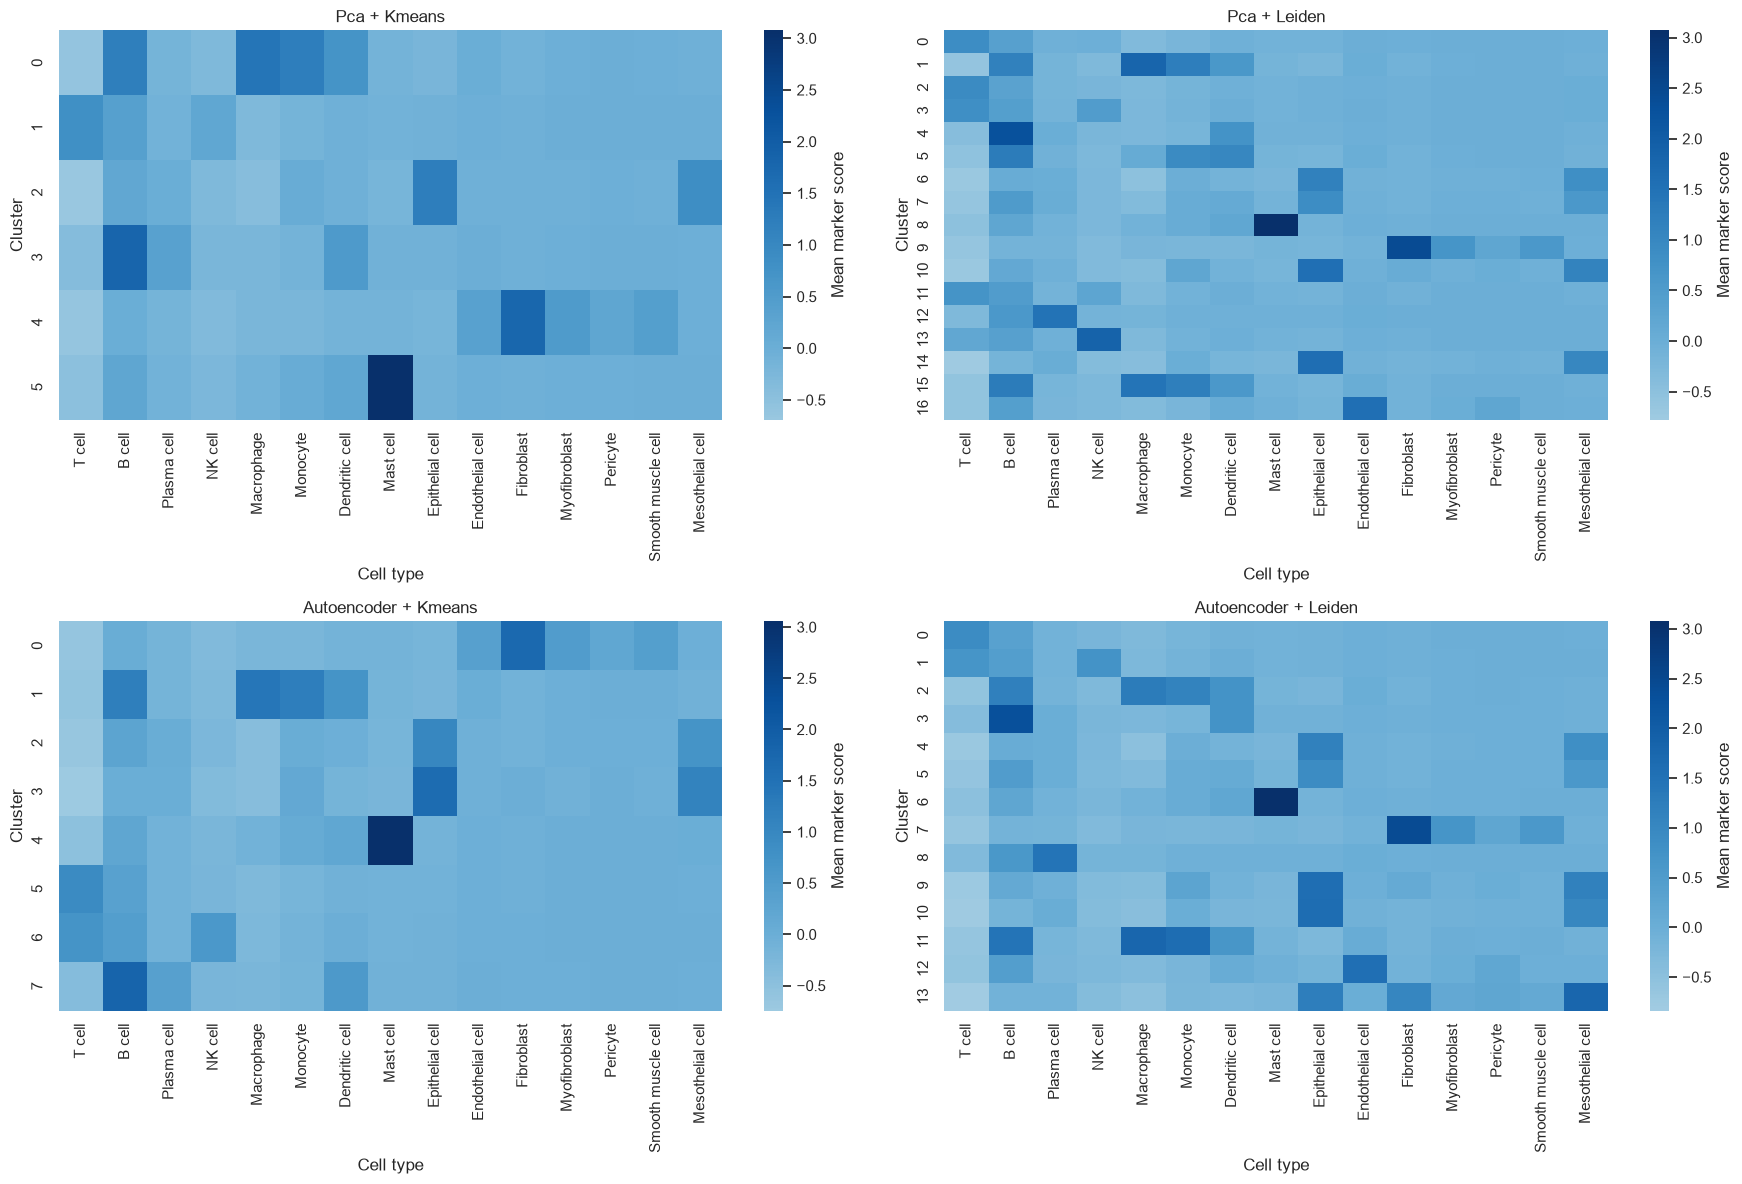

In [4]:
def numeric_cluster_order(values):
    return sorted(values.astype(str).unique(), key=int)

figure, axes = plt.subplots(2, 2, figsize=(18, 12))
for axis, (representation, method) in zip(axes.flat, specifications):
    values = marker_scores.loc[
        (marker_scores['representation'] == representation)
        & (marker_scores['method'] == method)
    ].pivot(index='cluster', columns='cell_type', values='marker_score')
    values.index = values.index.astype(str)
    values = values.reindex(index=numeric_cluster_order(values.index), columns=label_order)
    sns.heatmap(values, cmap='Blues', center=0, ax=axis, cbar_kws={'label': 'Mean marker score'})
    axis.set_title(f'{representation.title()} + {method.title()}')
    axis.set_xlabel('Cell type')
    axis.set_ylabel('Cluster')

figure.tight_layout()
figure.savefig(os.path.join(figure_dir, 'annotation_marker-score-heatmaps.png'), dpi=300, bbox_inches='tight')
plt.show()

## Annotation visualization

These panels visualize annotations assigned from CellMarker evidence using UMAP coordinates.

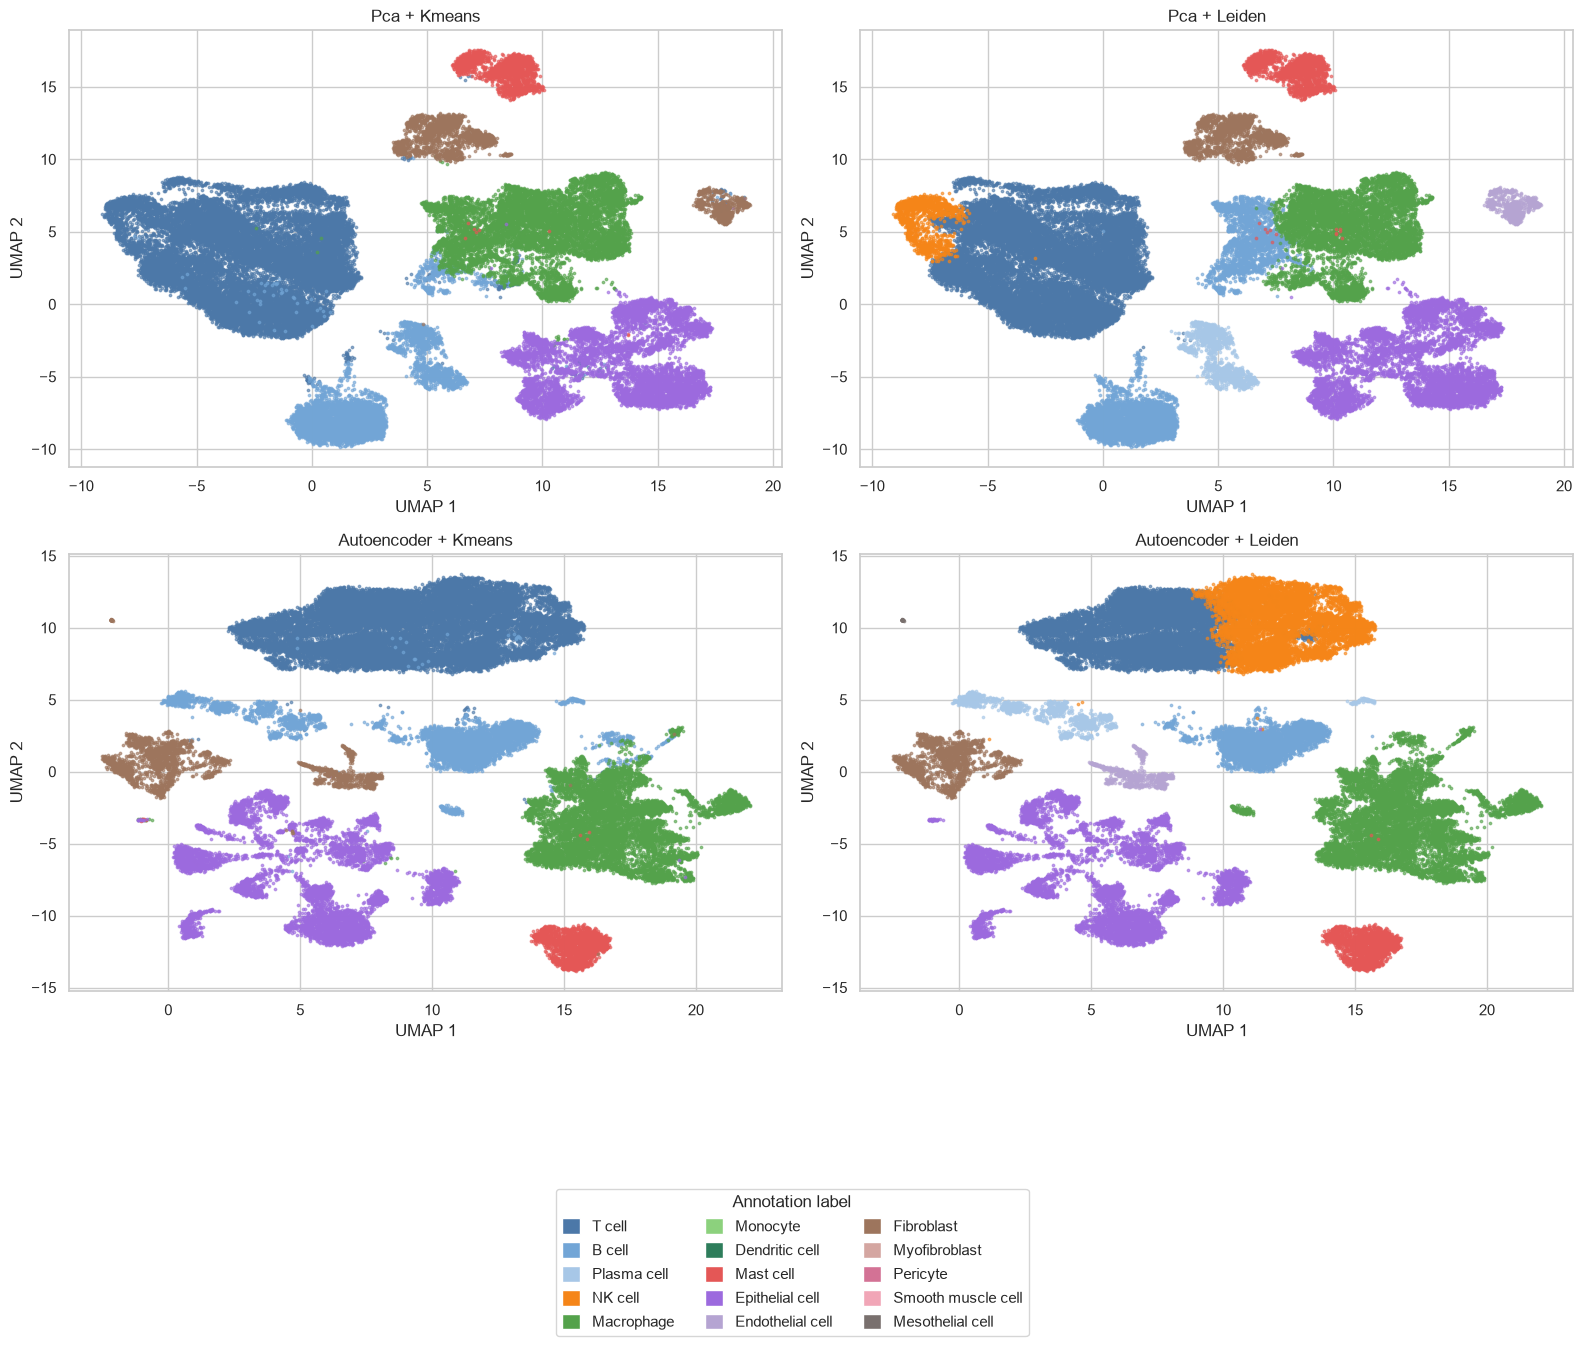

In [5]:
def calculate_umap(embedding):
    reducer = umap.UMAP(
        n_neighbors=representation_settings['umap_n_neighbors'],
        min_dist=representation_settings['umap_min_dist'],
        random_state=seed,
        n_jobs=1,
        compatibility_layout=True
    )
    return reducer.fit_transform(embedding)

coordinates = {
    'pca': calculate_umap(pca_embedding),
    'autoencoder': calculate_umap(autoencoder_embedding)
}
annotation_colors = {
    'T cell': '#4C78A8',
    'B cell': '#72A5D6',
    'Plasma cell': '#A7C7E7',
    'NK cell': '#F58518',
    'Macrophage': '#54A24B',
    'Monocyte': '#8CD17D',
    'Dendritic cell': '#2E7D5B',
    'Mast cell': '#E45756',
    'Epithelial cell': '#9C6ADE',
    'Endothelial cell': '#B5A4D2',
    'Fibroblast': '#9D755D',
    'Myofibroblast': '#D4A6A1',
    'Pericyte': '#D37295',
    'Smooth muscle cell': '#F1A6B7',
    'Mesothelial cell': '#79706E'
}

figure, axes = plt.subplots(2, 2, figsize=(16, 13))
for axis, (representation, method) in zip(axes.flat, specifications):
    assigned = annotation_labels[f'{representation}_{method}']
    values = coordinates[representation]
    for label in label_order:
        mask = assigned.to_numpy() == label
        axis.scatter(values[mask, 0], values[mask, 1], s=3, alpha=0.6, color=annotation_colors[label], label=label)
    axis.set_title(f'{representation.title()} + {method.title()}')
    axis.set_xlabel('UMAP 1')
    axis.set_ylabel('UMAP 2')

handles = [Patch(facecolor=annotation_colors[label]) for label in label_order]
figure.legend(handles, label_order, title='Annotation label', loc='lower center', bbox_to_anchor=(0.5, -0.04), ncol=3, handlelength=1.2, handleheight=1.2)
figure.tight_layout(rect=(0, 0.18, 1, 1))
figure.savefig(os.path.join(figure_dir, 'annotation_annotated-label-umap.png'), dpi=300, bbox_inches='tight')
plt.show()

## Reference label visualization

This separate visualization shows the dataset's source-provided reference labels on the same PCA and autoencoder UMAP coordinates. Shared cell identities use the same color as the annotation panels, and related lineages use coordinated shades.

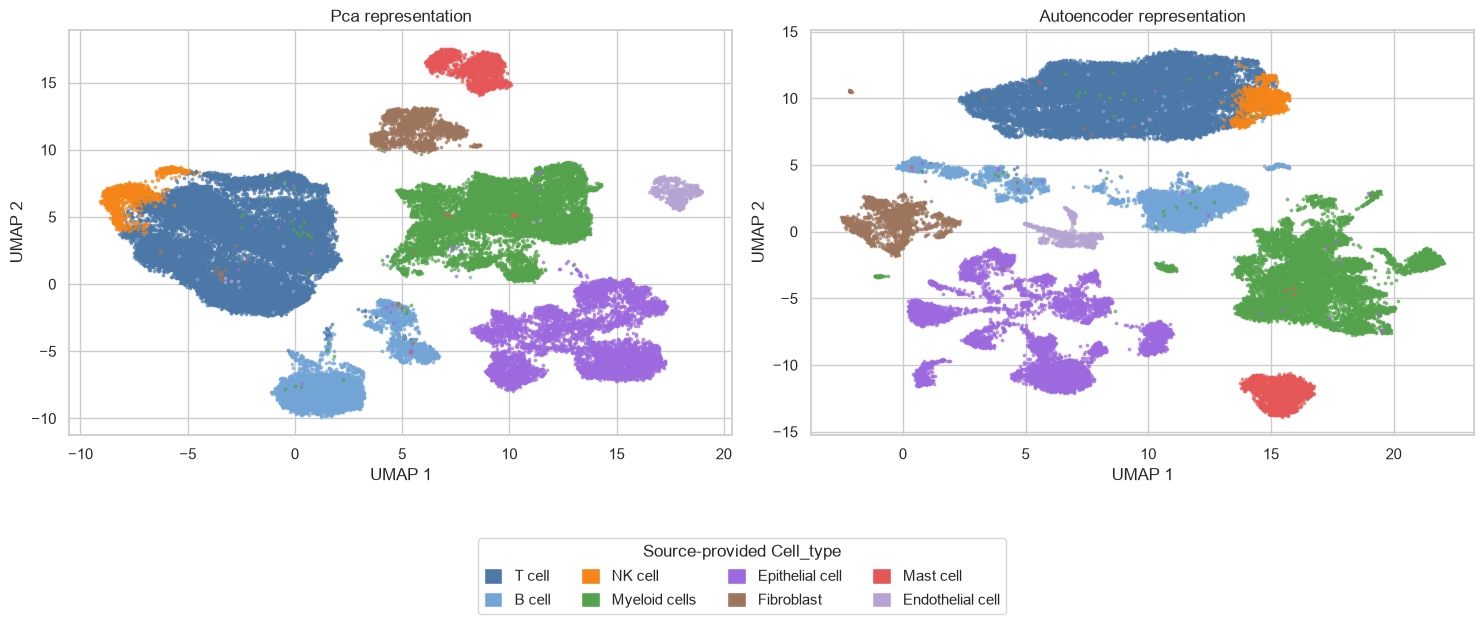

In [6]:
reference_annotations = pd.read_csv('data/raw/GSE131907_Lung_Cancer_cell_annotation.txt.gz', sep='\t')
reference_annotations['cell_id'] = (
    reference_annotations['Barcode'].astype(str)
    + '_'
    + reference_annotations['Sample'].astype(str)
)
reference_labels = reference_annotations.set_index('cell_id').reindex(assignments.index)['Cell_type']
if reference_labels.isna().any():
    raise ValueError('Reference Cell_type labels do not cover every clustered cell.')

reference_colors = {
    'T lymphocytes': annotation_colors['T cell'],
    'B lymphocytes': annotation_colors['B cell'],
    'NK cells': annotation_colors['NK cell'],
    'Myeloid cells': annotation_colors['Macrophage'],
    'Epithelial cells': annotation_colors['Epithelial cell'],
    'Fibroblasts': annotation_colors['Fibroblast'],
    'MAST cells': annotation_colors['Mast cell'],
    'Endothelial cells': annotation_colors['Endothelial cell']
}
reference_display_names = {
    'T lymphocytes': 'T cell',
    'B lymphocytes': 'B cell',
    'NK cells': 'NK cell',
    'Myeloid cells': 'Myeloid cells',
    'Epithelial cells': 'Epithelial cell',
    'Fibroblasts': 'Fibroblast',
    'MAST cells': 'Mast cell',
    'Endothelial cells': 'Endothelial cell'
}

figure, axes = plt.subplots(1, 2, figsize=(15, 6))
for axis, representation in zip(axes, ['pca', 'autoencoder']):
    values = coordinates[representation]
    for label in reference_order:
        mask = reference_labels.to_numpy() == label
        axis.scatter(values[mask, 0], values[mask, 1], s=3, alpha=0.6, color=reference_colors[label], label=label)
    axis.set_title(f'{representation.title()} representation')
    axis.set_xlabel('UMAP 1')
    axis.set_ylabel('UMAP 2')

handles = [Patch(facecolor=reference_colors[label]) for label in reference_order]
legend_labels = [reference_display_names[label] for label in reference_order]
figure.legend(handles, legend_labels, title='Source-provided Cell_type', loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=4, handlelength=1.2, handleheight=1.2)
figure.tight_layout(rect=(0, 0.15, 1, 1))
figure.savefig(os.path.join(figure_dir, 'annotation_reference-cell-type-umap.png'), dpi=300, bbox_inches='tight')
plt.show()

## Evaluation

For evaluation only, detailed annotation labels are mapped to the source broad-label ontology declared in `cell-type-markers.yml`.

In [7]:
overall_evaluation = annotation_evaluation.set_index(['representation', 'method'])
overall_evaluation.index.names = ['Representation', 'Method']
display(overall_evaluation.round(4))

for representation, method in specifications:
    display(Markdown(f'### {representation.title()} + {method.title()}'))
    per_type_table = per_type.loc[
        (per_type['representation'] == representation)
        & (per_type['method'] == method),
        ['cell_type', 'precision', 'recall', 'f1']
    ].set_index('cell_type')
    per_type_table.index.name = 'Cell type'
    display(per_type_table.round(4))

n_clusters  precision  accuracy  macro_f1
Representation Method                                           
pca            kmeans           6     0.6950    0.9434    0.7125
               leiden          17     0.9176    0.9318    0.9214
autoencoder    kmeans           8     0.6962    0.9497    0.7156
               leiden          14     0.8853    0.8305    0.8660

### Pca + Kmeans

,precision,recall,f1
Cell type,,,
T lymphocytes,0.9357,0.9950,0.9645
B lymphocytes,0.8947,0.9937,0.9416
NK cells,0.0000,0.0000,0.0000
Myeloid cells,0.9957,0.9334,0.9636
Epithelial cells,0.9992,0.9840,0.9915
Fibroblasts,0.7398,0.9806,0.8433
MAST cells,0.9950,0.9961,0.9956
Endothelial cells,0.0000,0.0000,0.0000


### Pca + Leiden

,precision,recall,f1
Cell type,,,
T lymphocytes,0.9885,0.9739,0.9811
B lymphocytes,0.6806,0.9972,0.8091
NK cells,0.6812,0.8435,0.7537
Myeloid cells,0.9988,0.7352,0.8469
Epithelial cells,0.9994,0.9970,0.9982
Fibroblasts,0.9988,0.9876,0.9932
MAST cells,0.9934,0.9994,0.9964
Endothelial cells,1.0000,0.9860,0.9930


### Autoencoder + Kmeans

,precision,recall,f1
Cell type,,,
T lymphocytes,0.9458,0.9959,0.9702
B lymphocytes,0.9152,0.9941,0.9530
NK cells,0.0000,0.0000,0.0000
Myeloid cells,0.9984,0.9519,0.9746
Epithelial cells,0.9977,0.9948,0.9962
Fibroblasts,0.7225,0.9929,0.8364
MAST cells,0.9901,0.9989,0.9945
Endothelial cells,0.0000,0.0000,0.0000


### Autoencoder + Leiden

,precision,recall,f1
Cell type,,,
T lymphocytes,0.9974,0.6050,0.7532
B lymphocytes,0.9827,0.9953,0.9890
NK cells,0.1212,1.0000,0.2161
Myeloid cells,0.9975,0.9921,0.9948
Epithelial cells,0.9943,0.9969,0.9956
Fibroblasts,0.9976,0.9788,0.9881
MAST cells,0.9967,0.9983,0.9975
Endothelial cells,0.9953,0.9922,0.9938


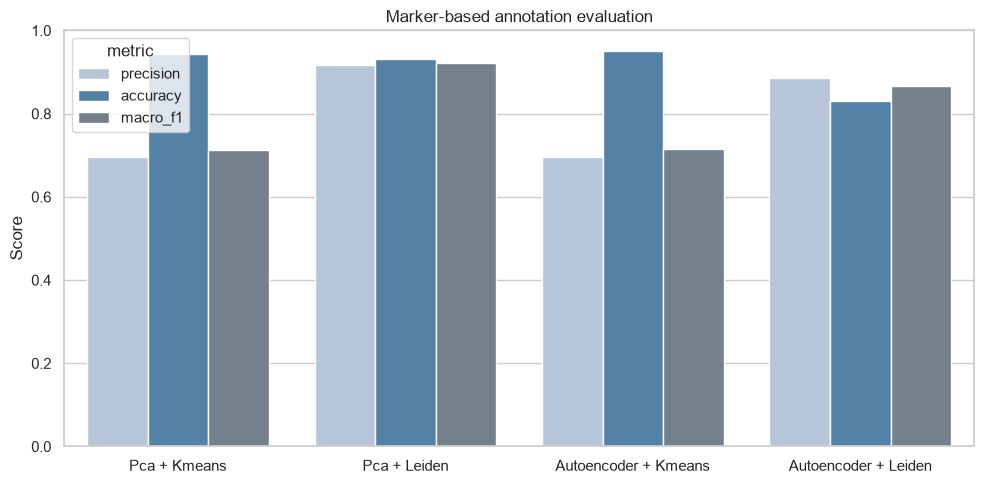

In [8]:
annotation_plot = annotation_evaluation.copy()
annotation_plot['combination'] = annotation_plot['representation'].str.title() + ' + ' + annotation_plot['method'].str.title()
annotation_plot = annotation_plot.melt(id_vars='combination', value_vars=['precision', 'accuracy', 'macro_f1'], var_name='metric', value_name='value')

figure, axis = plt.subplots(figsize=(10, 5))
sns.barplot(data=annotation_plot, x='combination', y='value', hue='metric', palette=['lightsteelblue', 'steelblue', 'slategray'], ax=axis)
axis.set_xlabel('')
axis.set_ylabel('Score')
axis.set_title('Marker-based annotation evaluation')
axis.set_ylim(0, 1)
figure.tight_layout()
figure.savefig(os.path.join(figure_dir, 'annotation_annotation-evaluation.png'), dpi=300, bbox_inches='tight')
plt.show()

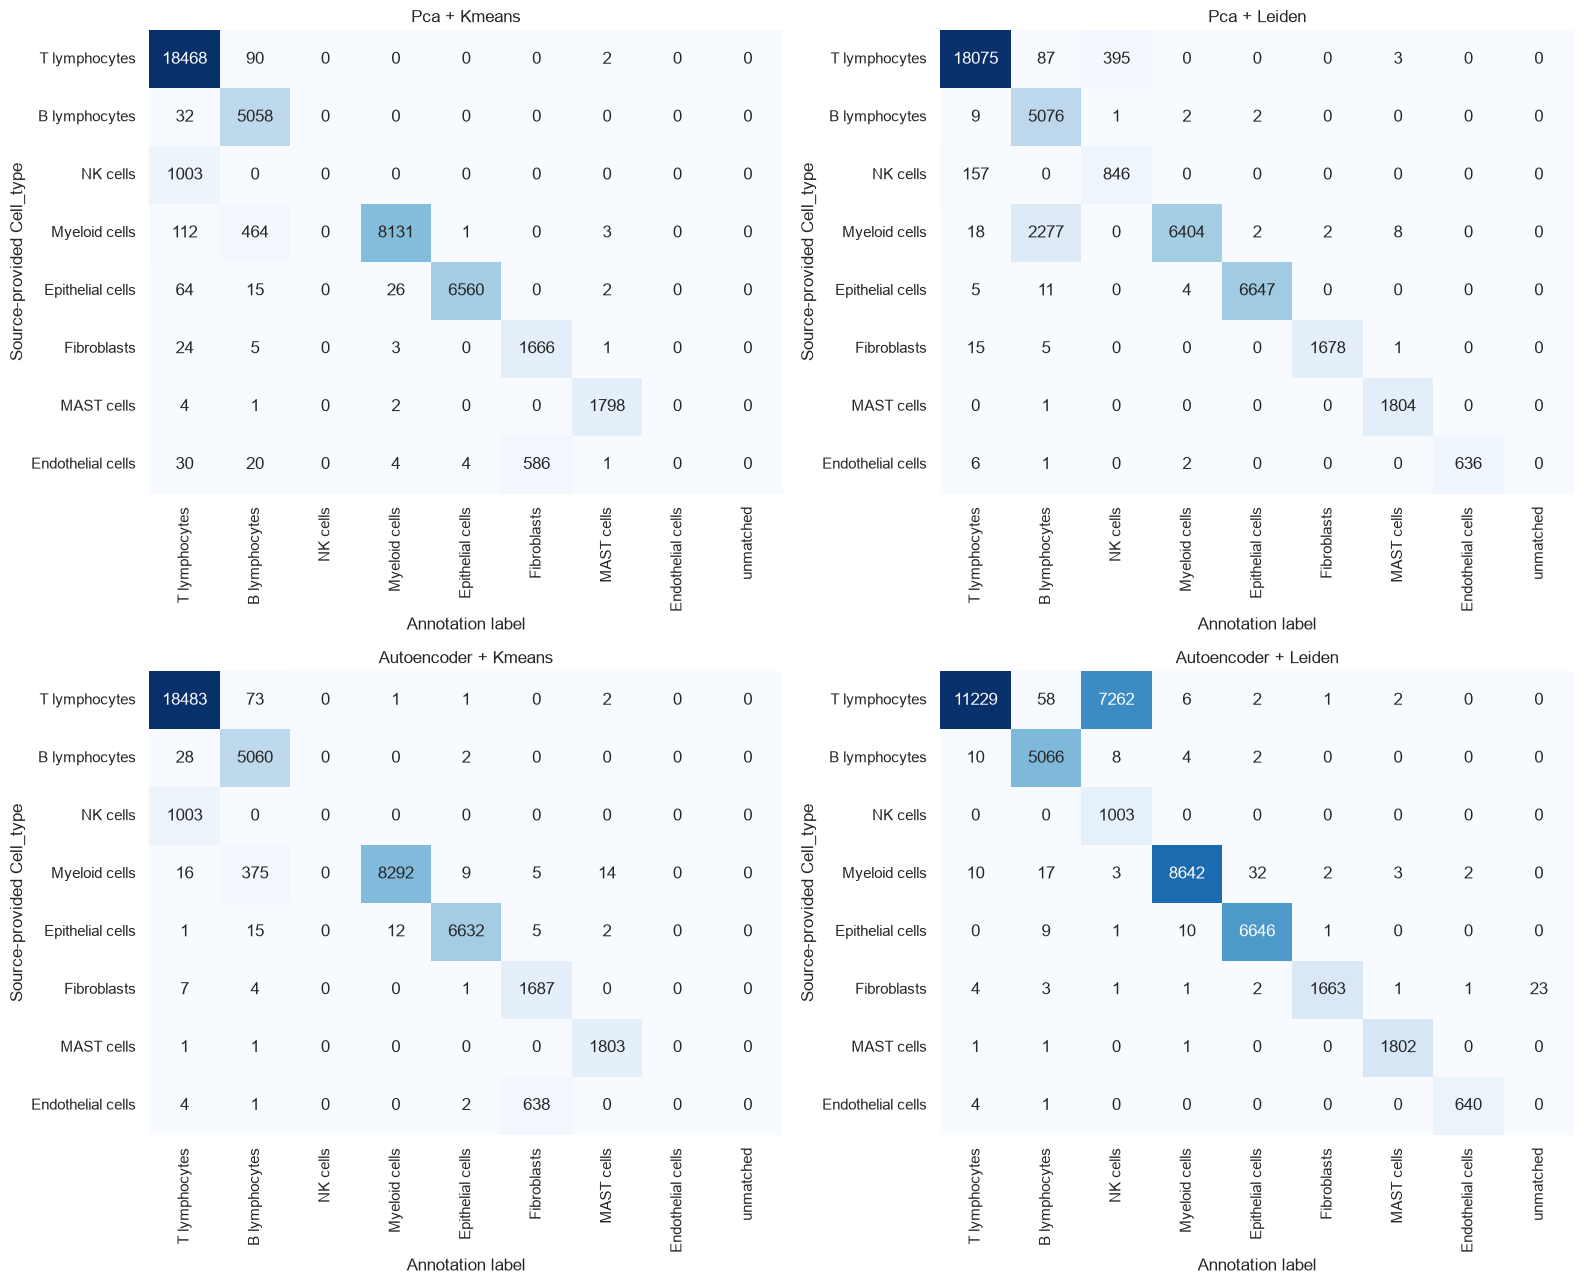

In [9]:
figure, axes = plt.subplots(2, 2, figsize=(16, 13))
for axis, (representation, method) in zip(axes.flat, specifications):
    values = confusion.loc[
        (confusion['representation'] == representation)
        & (confusion['method'] == method)
    ].pivot(index='reference_cell_type', columns='predicted_label', values='cells')
    values = values.reindex(index=reference_order, columns=reference_order + ['unmatched'], fill_value=0)
    sns.heatmap(values, cmap='Blues', annot=True, fmt='g', ax=axis, cbar=False)
    axis.set_title(f'{representation.title()} + {method.title()}')
    axis.set_xlabel('Annotation label')
    axis.set_ylabel('Source-provided Cell_type')

figure.tight_layout()
figure.savefig(os.path.join(figure_dir, 'annotation_confusion-matrices.png'), dpi=300, bbox_inches='tight')
plt.show()